# Lab 1 - Phần 1.1: Thống kê mô tả (Descriptive Statistics)
**Nội dung:** bài làm mẫu (COVID, Marketing Campaign) + Bài tập 1 (Red Wine Quality) + Bài tập 2 (Pima Indians Diabetes).

**Dữ liệu cần có trong thư mục `data/`** (xem `data/README.md`):
`owid-covid-data.csv`, `marketing_campaign.csv`, `winequality-red.csv`, `diabetes.csv`

In [1]:
import sys; sys.path.append(".")
from utils import *
from scipy import stats

## A. Bài làm mẫu
### A.1 COVID-19: thống kê mô tả cột `new_cases`

In [2]:
covid = load_table("owid-covid-data.csv", "covid-data.csv", "*covid*.csv")
cols = ["iso_code", "continent", "location", "date", "total_cases", "new_cases"]
covid = covid[[c for c in cols if c in covid.columns]]
overview(covid, "COVID")

# Làm sạch: (1) chỉ giữ quốc gia/vùng lãnh thổ (bỏ dòng tổng hợp: châu lục, nhóm thu nhập, EU... có continent = NaN)
n0 = len(covid)
if "continent" in covid.columns:
    covid = covid[covid["continent"].notna()]
# (2) bỏ dòng trùng (location, date): giữ dòng có new_cases (NaN xếp cuối nên keep="first" giữ dòng có giá trị)
covid = (covid.sort_values(["location", "date", "new_cases"])
              .drop_duplicates(["location", "date"], keep="first"))
print(f"Sau khi bỏ dòng tổng hợp và dòng trùng: {n0:,} -> {len(covid):,} dòng, {covid['location'].nunique()} quốc gia/vùng lãnh thổ")


[Đọc dữ liệu] data\owid-covid-data.csv
===== COVID =====
Kích thước: 429435 dòng x 6 cột
Số dòng trùng lặp: 0


,dtype,missing,missing_%,n_unique
iso_code,object,0,0.00,255
continent,object,26525,6.18,6
location,object,0,0.00,255
date,object,0,0.00,1688
total_cases,float64,17631,4.11,36694
new_cases,float64,19276,4.49,14158


,iso_code,continent,location,date,total_cases,new_cases
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0


Sau khi bỏ dòng tổng hợp và dòng trùng: 429,435 -> 401,502 dòng, 243 quốc gia/vùng lãnh thổ


In [3]:
x = covid["new_cases"].dropna()
summary = pd.Series({
    "mean": np.mean(x),
    "median": np.median(x),
    "mode": stats.mode(x, keepdims=False).mode,
    "variance": np.var(x),
    "std": np.std(x),
    "min": np.min(x),
    "max": np.max(x),
    "range": np.ptp(x),
    "percentile 60": np.percentile(x, 60),
    "Q1": np.percentile(x, 25),
    "Q3": np.percentile(x, 75),
    "IQR": stats.iqr(x),
})
display(summary.to_frame("new_cases"))
print(f"mean/median = {np.mean(x) / np.median(x):.1f}  -> mean lớn hơn median rất nhiều = phân phối lệch phải mạnh")

,new_cases
mean,1.989215e+03
median,0.000000e+00
mode,0.000000e+00
variance,7.371624e+09
std,8.585816e+04
min,0.000000e+00
max,4.047548e+07
range,4.047548e+07
percentile 60,0.000000e+00
Q1,0.000000e+00


mean/median = inf  -> mean lớn hơn median rất nhiều = phân phối lệch phải mạnh


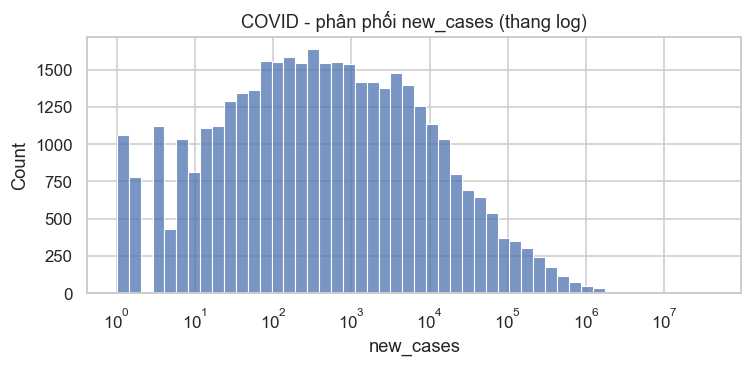

[Đã lưu] figures\s11_covid_new_cases_hist.png


In [4]:
plt.figure(figsize=(7, 3.5))
sns.histplot(x[x > 0], log_scale=True, bins=50)
plt.title("COVID - phân phối new_cases (thang log)")
save_fig("s11_covid_new_cases_hist")

### A.2 Marketing Campaign: xử lý trùng lặp, thay thế giá trị, giá trị thiếu

In [5]:
mk = load_table("marketing_campaign.csv", "*marketing*.csv")
cols = ["ID", "Year_Birth", "Education", "Marital_Status", "Income", "Kidhome",
        "Teenhome", "Dt_Customer", "Recency", "NumStorePurchases", "NumWebVisitsMonth"]
mk = mk[[c for c in cols if c in mk.columns]].copy()
print("Số dòng trùng lặp:", mk.duplicated().sum())
mk = mk.drop_duplicates()

# Thay thế giá trị (replace)
mk["Teenhome_label"] = mk["Teenhome"].replace({0: "no teen", 1: "has teen", 2: "has teen"})
mk["Dt_Customer"] = pd.to_datetime(mk["Dt_Customer"], dayfirst=True, errors="coerce")
display(mk[["Teenhome", "Teenhome_label", "Dt_Customer"]].head())

[Đọc dữ liệu] data\marketing_campaign.csv
Số dòng trùng lặp: 0


,Teenhome,Teenhome_label,Dt_Customer
0,0,no teen,2012-09-04
1,1,has teen,2014-03-08
2,0,no teen,2013-08-21
3,0,no teen,2014-02-10
4,0,no teen,2014-01-19


In [6]:
print("Giá trị thiếu theo cột:\n", mk.isna().sum()[mk.isna().sum() > 0])

# 3 cách xử lý giá trị thiếu của cột Income
mk["Income_fill0"] = mk["Income"].fillna(0)                      # cách 1: điền 0 (làm lệch phân phối)
mk["Income_fill_median"] = mk["Income"].fillna(mk["Income"].median())  # cách 2: điền median (khuyến nghị)
mk_dropna = mk.dropna(subset=["Income"])                         # cách 3: xóa dòng thiếu
print(f"\nShape gốc: {mk.shape} | sau dropna: {mk_dropna.shape}")
print("\nSo sánh thống kê Income theo từng cách xử lý:")
display(mk[["Income", "Income_fill0", "Income_fill_median"]].agg(["mean", "median", "std"]).round(1))

Giá trị thiếu theo cột:
 Income    24
dtype: int64

Shape gốc: (2240, 14) | sau dropna: (2216, 14)

So sánh thống kê Income theo từng cách xử lý:


,Income,Income_fill0,Income_fill_median
mean,52247.3,51687.5,52238.0
median,51381.5,51075.0,51381.5
std,25173.1,25609.3,25038.0


## B. Bài tập 1 - Red Wine Quality

In [7]:
wine = load_table("winequality-red.csv", "*wine*red*.csv", "winequality*.csv", "*wine*.csv")
overview(wine, "Red Wine Quality")

[Đọc dữ liệu] data\winequality-red.csv
===== Red Wine Quality =====
Kích thước: 1599 dòng x 12 cột
Số dòng trùng lặp: 240


,dtype,missing,missing_%,n_unique
fixed acidity,float64,0,0.0,96
volatile acidity,float64,0,0.0,143
citric acid,float64,0,0.0,80
residual sugar,float64,0,0.0,91
chlorides,float64,0,0.0,153
free sulfur dioxide,float64,0,0.0,60
total sulfur dioxide,float64,0,0.0,144
density,float64,0,0.0,436
pH,float64,0,0.0,89
sulphates,float64,0,0.0,96


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


**Bước 1 - Dữ liệu trùng lặp & giá trị thiếu**

In [8]:
n_dup = wine.duplicated().sum()
print(f"Số dòng trùng lặp: {n_dup} ({n_dup / len(wine):.1%}) | Số giá trị thiếu: {wine.isna().sum().sum()}")
wine_clean = wine.drop_duplicates().reset_index(drop=True)
print("Kích thước sau khi bỏ trùng:", wine_clean.shape)

Số dòng trùng lặp: 240 (15.0%) | Số giá trị thiếu: 0
Kích thước sau khi bỏ trùng: (1359, 12)


**Bước 2 - Các độ đo thống kê mô tả:** mean, median, mode, variance, std, range, Q1, Q3, IQR, skewness, kurtosis

In [9]:
desc = describe_full(wine_clean)
display(desc)
desc.to_csv(OUT_DIR / "wine_describe.csv")

,count,missing,mean,median,mode,std,var,min,max,range,Q1,Q3,IQR,skew,kurtosis
fixed acidity,1359,0,8.311,7.900,7.200,1.737,3.017,4.600,15.900,11.300,7.100,9.200,2.100,0.941,1.050
volatile acidity,1359,0,0.529,0.520,0.500,0.183,0.034,0.120,1.580,1.460,0.390,0.640,0.250,0.729,1.249
citric acid,1359,0,0.272,0.260,0.000,0.196,0.038,0.000,1.000,1.000,0.090,0.430,0.340,0.313,-0.789
residual sugar,1359,0,2.523,2.200,2.000,1.352,1.829,0.900,15.500,14.600,1.900,2.600,0.700,4.548,29.365
chlorides,1359,0,0.088,0.079,0.080,0.049,0.002,0.012,0.611,0.599,0.070,0.091,0.021,5.502,38.625
free sulfur dioxide,1359,0,15.893,14.000,6.000,10.447,109.145,1.000,72.000,71.000,7.000,21.000,14.000,1.227,1.893
total sulfur dioxide,1359,0,46.826,38.000,28.000,33.409,1116.158,6.000,289.000,283.000,22.000,63.000,41.000,1.540,4.042
density,1359,0,0.997,0.997,0.997,0.002,0.000,0.990,1.004,0.014,0.996,0.998,0.002,0.045,0.831
pH,1359,0,3.310,3.310,3.300,0.155,0.024,2.740,4.010,1.270,3.210,3.400,0.190,0.232,0.880
sulphates,1359,0,0.659,0.620,0.540,0.171,0.029,0.330,2.000,1.670,0.550,0.730,0.180,2.407,11.102


In [10]:
# Cột lệch mạnh (|skew| > 1) và so sánh mean - median
skew = desc[["mean", "median", "skew"]].copy()
skew["mean-median"] = (skew["mean"] - skew["median"]).round(3)
print("Các cột lệch mạnh (|skew| > 1):")
display(skew[skew["skew"].abs() > 1].sort_values("skew", ascending=False))

Các cột lệch mạnh (|skew| > 1):


,mean,median,skew,mean-median
chlorides,0.088,0.079,5.502,0.009
residual sugar,2.523,2.200,4.548,0.323
sulphates,0.659,0.620,2.407,0.039
total sulfur dioxide,46.826,38.000,1.540,8.826
free sulfur dioxide,15.893,14.000,1.227,1.893


**Bước 3 - Phát hiện ngoại lai (quy tắc IQR 1.5)**

,column,lower_fence,upper_fence,n_outliers,outlier_%
0,residual sugar,0.85000,3.65000,126,9.27
1,chlorides,0.03850,0.12250,87,6.40
2,sulphates,0.28000,1.00000,55,4.05
3,total sulfur dioxide,-39.50000,124.50000,45,3.31
4,fixed acidity,3.95000,12.35000,41,3.02
5,density,0.99227,1.00115,35,2.58
6,pH,2.92500,3.68500,28,2.06
7,free sulfur dioxide,-14.00000,42.00000,26,1.91
8,volatile acidity,0.01500,1.01500,19,1.40
9,alcohol,7.10000,13.50000,12,0.88


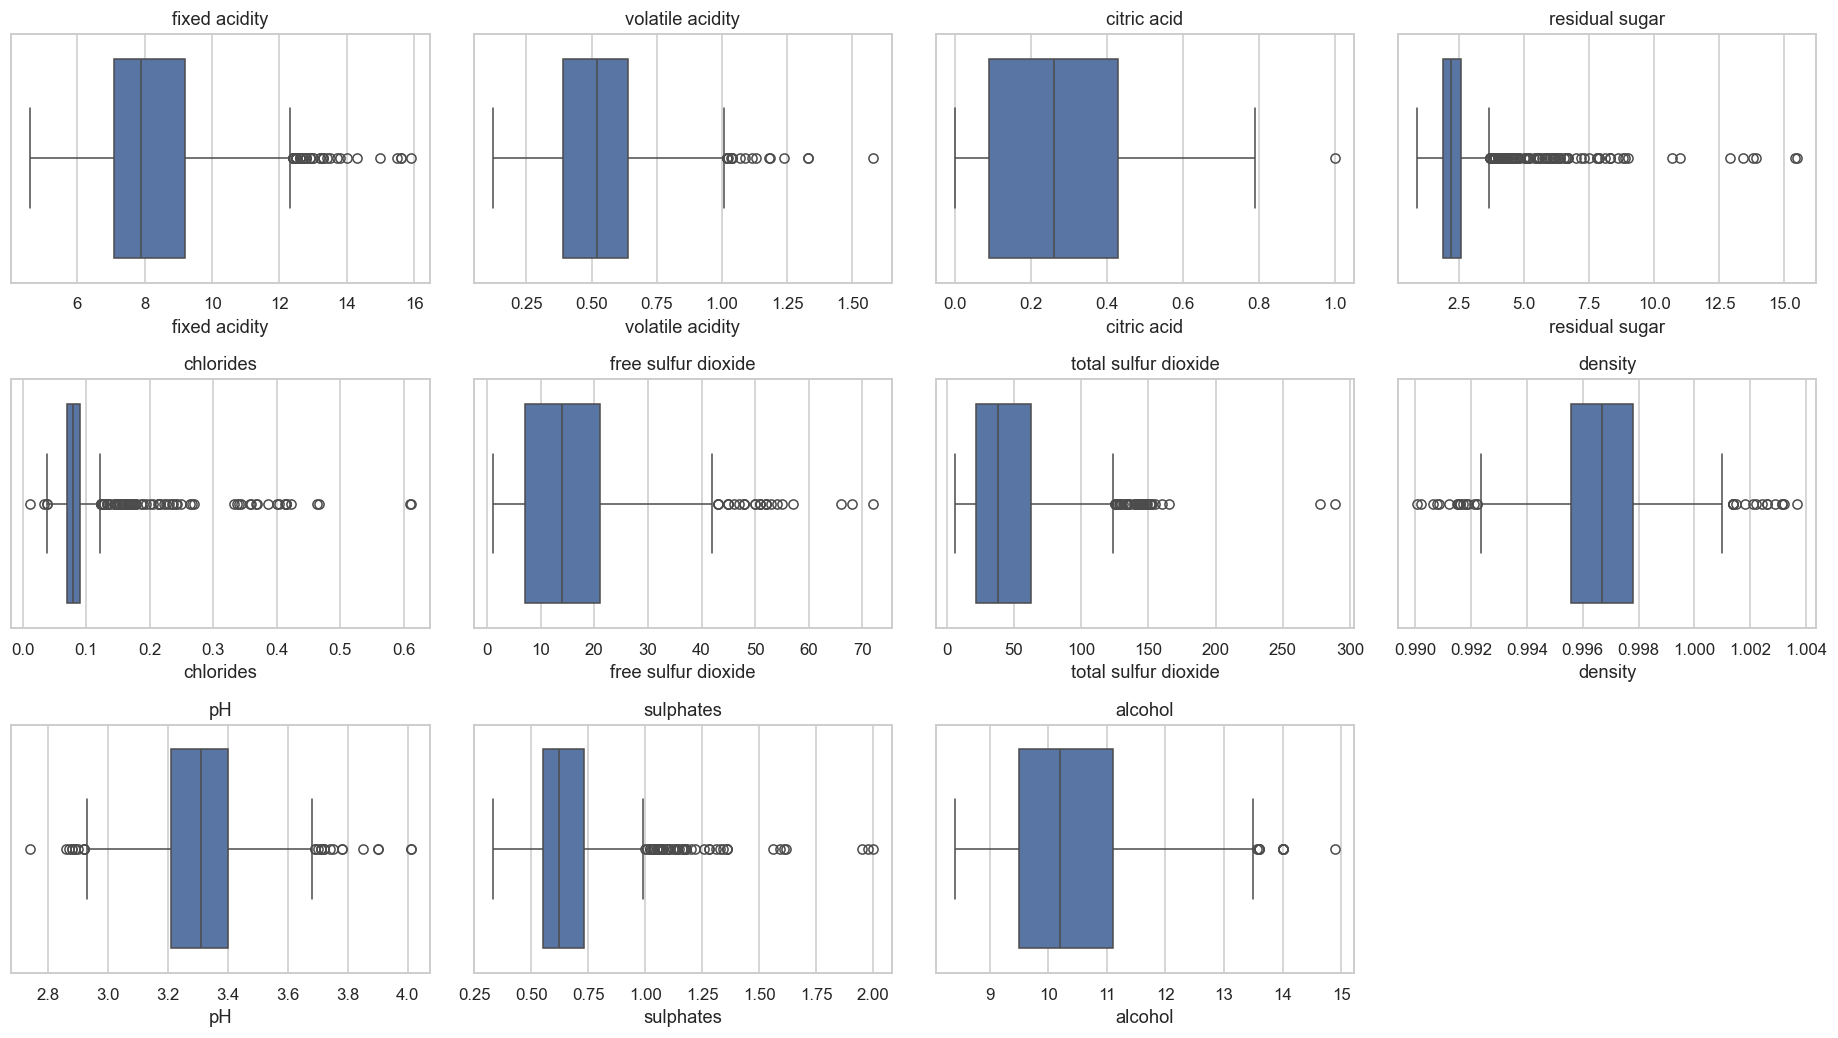

[Đã lưu] figures\s11_wine_boxplots.png


In [11]:
out_tbl = outlier_table(wine_clean.drop(columns=["quality"]))
display(out_tbl)
grid_plot(wine_clean.drop(columns=["quality"]), wine_clean.drop(columns=["quality"]).columns,
          kind="box", ncols=4, name="s11_wine_boxplots")

**Bước 4 - Phân phối từng biến và biến mục tiêu `quality`**

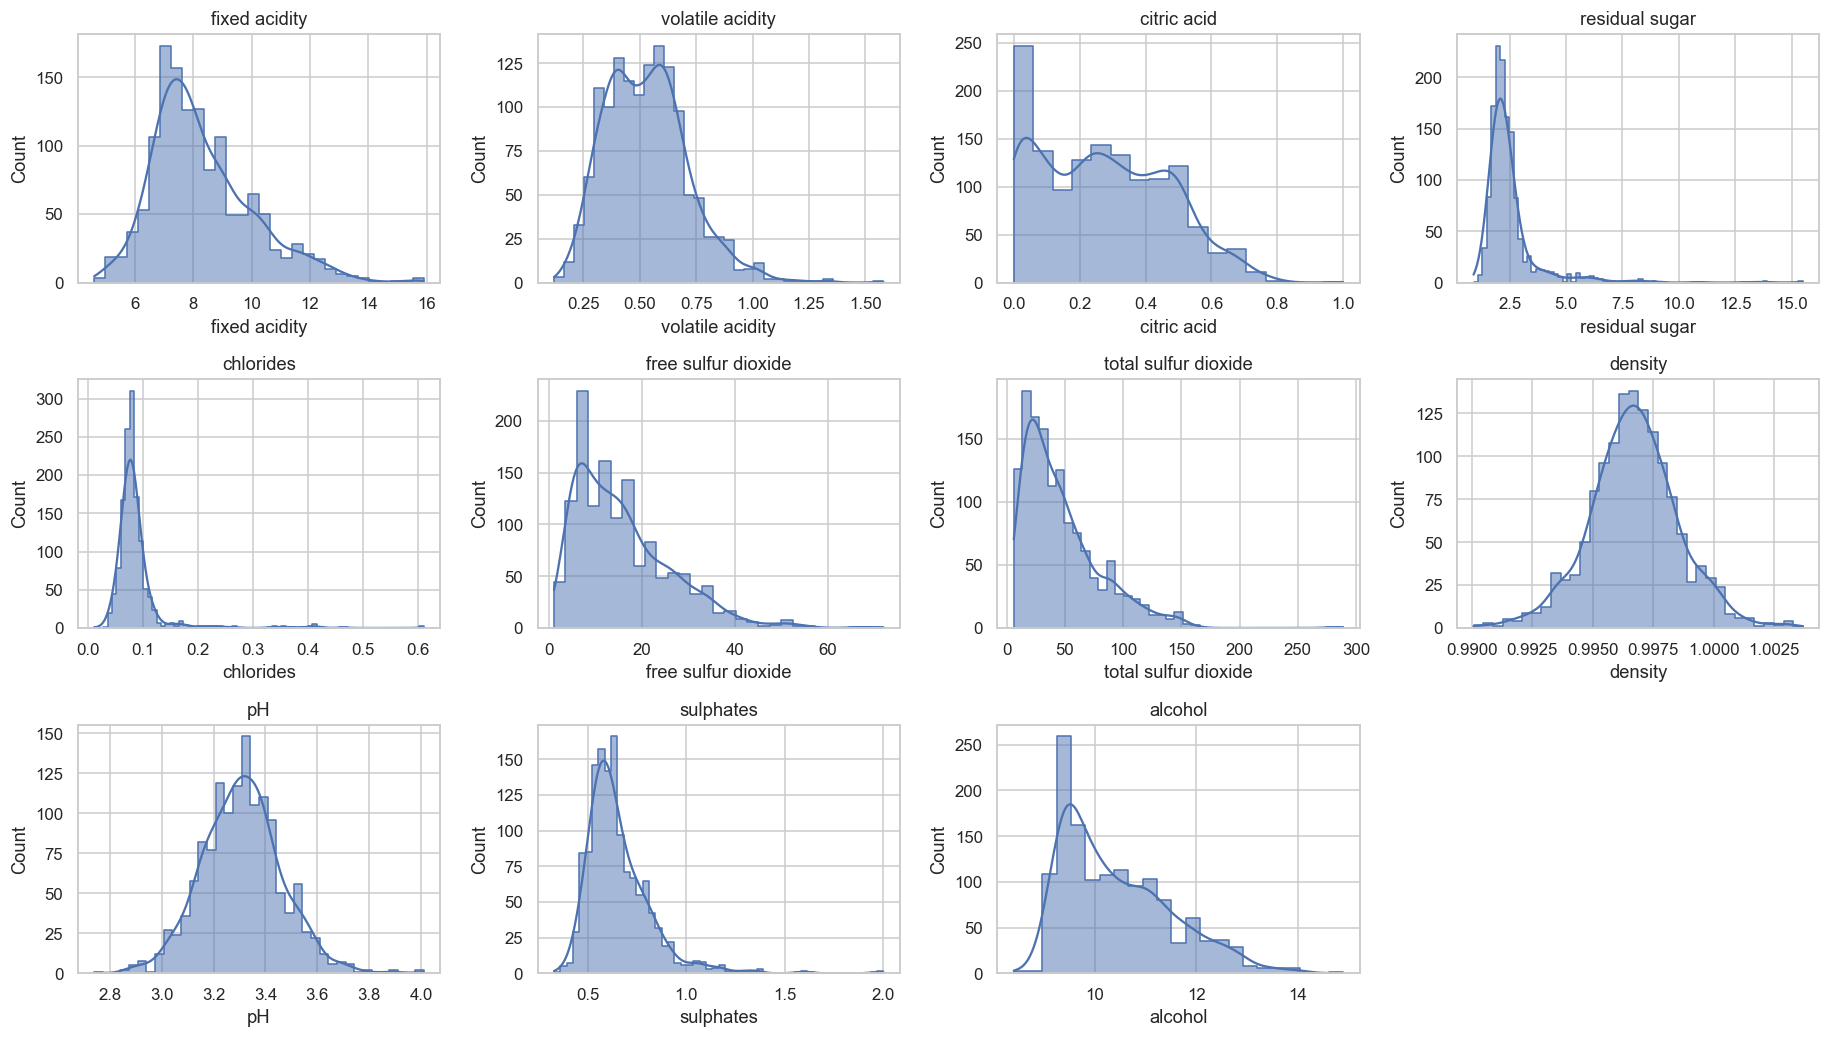

[Đã lưu] figures\s11_wine_hist.png


In [12]:
grid_plot(wine_clean.drop(columns=["quality"]), wine_clean.drop(columns=["quality"]).columns,
          kind="hist", ncols=4, name="s11_wine_hist")

,count,percent
quality,,
3,10,0.74
4,53,3.90
5,577,42.46
6,535,39.37
7,167,12.29
8,17,1.25


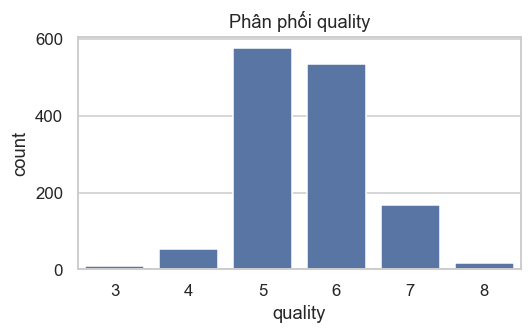

[Đã lưu] figures\s11_wine_quality_count.png


In [13]:
q = wine_clean["quality"].value_counts().sort_index()
display(pd.DataFrame({"count": q, "percent": (q / q.sum() * 100).round(2)}))
plt.figure(figsize=(5, 3.2)); sns.countplot(data=wine_clean, x="quality")
plt.title("Phân phối quality"); save_fig("s11_wine_quality_count")

In [14]:
# Thống kê theo nhóm chất lượng: biến nào thay đổi rõ theo quality?
display(wine_clean.groupby("quality").mean().round(3))

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,8.360,0.885,0.171,2.635,0.122,11.000,24.900,0.997,3.398,0.570,9.955
4,7.779,0.694,0.174,2.694,0.091,12.264,36.245,0.997,3.382,0.596,10.265
5,8.171,0.579,0.245,2.510,0.094,17.161,57.406,0.997,3.301,0.624,9.889
6,8.337,0.496,0.279,2.457,0.085,15.637,40.817,0.997,3.318,0.675,10.659
7,8.859,0.404,0.372,2.717,0.077,13.994,35.449,0.996,3.290,0.743,11.491
8,8.441,0.428,0.383,2.576,0.068,13.765,34.471,0.995,3.274,0.775,12.159


**Bước 5 - Xử lý ngoại lai (winsorize theo IQR) và so sánh trước/sau**

In [15]:
cols_out = out_tbl.head(3)["column"].tolist()
wine_w = clip_outliers_iqr(wine_clean, cols_out)
cmp = pd.concat({"trước": wine_clean[cols_out].agg(["mean", "std", "max"]),
                 "sau": wine_w[cols_out].agg(["mean", "std", "max"])}, axis=1).round(3)
display(cmp)

trước                                sau                    
     residual sugar chlorides sulphates residual sugar chlorides sulphates
mean          2.523     0.088     0.659          2.324     0.081     0.650
std           1.352     0.049     0.171          0.608     0.018     0.137
max          15.500     0.611     2.000          3.650     0.122     1.000

## C. Bài tập 2 - Pima Indians Diabetes

In [16]:
db, target = load_diabetes(clean_zeros=False)
overview(db, "Pima Diabetes")
print("Biến mục tiêu:", target)

[Đọc dữ liệu] data\diabetes.csv
===== Pima Diabetes =====
Kích thước: 768 dòng x 9 cột
Số dòng trùng lặp: 0


,dtype,missing,missing_%,n_unique
Pregnancies,int64,0,0.0,17
Glucose,int64,0,0.0,136
BloodPressure,int64,0,0.0,47
SkinThickness,int64,0,0.0,51
Insulin,int64,0,0.0,186
BMI,float64,0,0.0,248
DiabetesPedigreeFunction,float64,0,0.0,517
Age,int64,0,0.0,52
Outcome,int64,0,0.0,2


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Biến mục tiêu: Outcome


**Bước 1 - Giá trị 0 "ẩn" (thực chất là thiếu)** ở các cột Glucose, BloodPressure, SkinThickness, Insulin, BMI

In [17]:
med_cols = [c for c in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"] if c in db.columns]
zero_cnt = pd.DataFrame({"số giá trị = 0": (db[med_cols] == 0).sum(),
                         "tỷ lệ %": ((db[med_cols] == 0).mean() * 100).round(2)})
display(zero_cnt)

,số giá trị = 0,tỷ lệ %
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


In [18]:
db_nan = db.copy()
db_nan[med_cols] = db_nan[med_cols].replace(0, np.nan)
print("Giá trị thiếu sau khi chuyển 0 -> NaN:\n", db_nan.isna().sum()[db_nan.isna().sum() > 0])

# Điền median theo từng nhóm Outcome (chính xác hơn median toàn cục)
db_fill = db_nan.copy()
for c in med_cols:
    db_fill[c] = db_fill[c].fillna(db_fill.groupby(target)[c].transform("median"))
print("Còn thiếu sau khi điền:", db_fill.isna().sum().sum())

Giá trị thiếu sau khi chuyển 0 -> NaN:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
Còn thiếu sau khi điền: 0


**Bước 2 - Thống kê mô tả trước và sau xử lý**

In [19]:
print("TRƯỚC xử lý (giữ nguyên giá trị 0):"); display(describe_full(db[med_cols]))
print("SAU xử lý:"); display(describe_full(db_fill[med_cols]))

TRƯỚC xử lý (giữ nguyên giá trị 0):


,count,missing,mean,median,mode,std,var,min,max,range,Q1,Q3,IQR,skew,kurtosis
Glucose,768,0,120.895,117.0,99.0,31.973,1022.248,0.0,199.0,199.0,99.0,140.25,41.25,0.174,0.641
BloodPressure,768,0,69.105,72.0,70.0,19.356,374.647,0.0,122.0,122.0,62.0,80.00,18.00,-1.844,5.180
SkinThickness,768,0,20.536,23.0,0.0,15.952,254.473,0.0,99.0,99.0,0.0,32.00,32.00,0.109,-0.520
Insulin,768,0,79.799,30.5,0.0,115.244,13281.180,0.0,846.0,846.0,0.0,127.25,127.25,2.272,7.214
BMI,768,0,31.993,32.0,32.0,7.884,62.160,0.0,67.1,67.1,27.3,36.60,9.30,-0.429,3.290


SAU xử lý:


,count,missing,mean,median,mode,std,var,min,max,range,Q1,Q3,IQR,skew,kurtosis
Glucose,768,0,121.677,117.00,99.0,30.464,928.065,44.0,199.0,155.0,99.75,140.25,40.5,0.532,-0.268
BloodPressure,768,0,72.389,72.00,70.0,12.106,146.556,24.0,122.0,98.0,64.00,80.00,16.0,0.141,1.085
SkinThickness,768,0,29.090,28.00,27.0,8.891,79.047,7.0,99.0,92.0,25.00,32.00,7.0,0.817,5.068
Insulin,768,0,141.754,102.50,102.5,89.101,7938.961,14.0,846.0,832.0,102.50,169.50,67.0,3.028,13.853
BMI,768,0,32.435,32.05,30.1,6.880,47.341,18.2,67.1,48.9,27.50,36.60,9.1,0.606,0.915


**Bước 3 - Thống kê theo nhóm `Outcome` (mắc / không mắc bệnh)**

In [20]:
display(db_fill.groupby(target).agg(["mean", "median", "std"]).T.round(2))
print("Tỷ lệ lớp:"); display(db_fill[target].value_counts(normalize=True).round(3).to_frame("tỷ lệ"))

Outcome                               0       1
Pregnancies              mean      3.30    4.87
                         median    2.00    4.00
                         std       3.02    3.74
Glucose                  mean    110.62  142.30
                         median  107.00  140.00
                         std      24.70   29.49
BloodPressure            mean     70.84   75.27
                         median   70.00   74.50
                         std      11.93   11.93
SkinThickness            mean     27.17   32.67
                         median   27.00   32.00
                         std       8.52    8.47
Insulin                  mean    117.17  187.62
                         median  102.50  169.50
                         std      75.69   94.11
BMI                      mean     30.85   35.40
                         median   30.10   34.30
                         std       6.50    6.59
DiabetesPedigreeFunction mean      0.43    0.55
                         median    0.34    0.45
                         std       0.30    0.37
Age                      mean     31.19   37.07
                         median   27.00   36.00
                         std      11.67   10.97

Tỷ lệ lớp:


,tỷ lệ
Outcome,
0,0.651
1,0.349


**Bước 4 - Ngoại lai và phân phối**

,column,lower_fence,upper_fence,n_outliers,outlier_%
0,SkinThickness,14.50,42.50,87,11.33
1,Insulin,2.00,270.00,51,6.64
2,DiabetesPedigreeFunction,-0.33,1.20,29,3.78
3,BloodPressure,40.00,104.00,14,1.82
4,Age,-1.50,66.50,9,1.17
5,BMI,13.85,50.25,8,1.04
6,Pregnancies,-6.50,13.50,4,0.52
7,Glucose,39.00,201.00,0,0.00


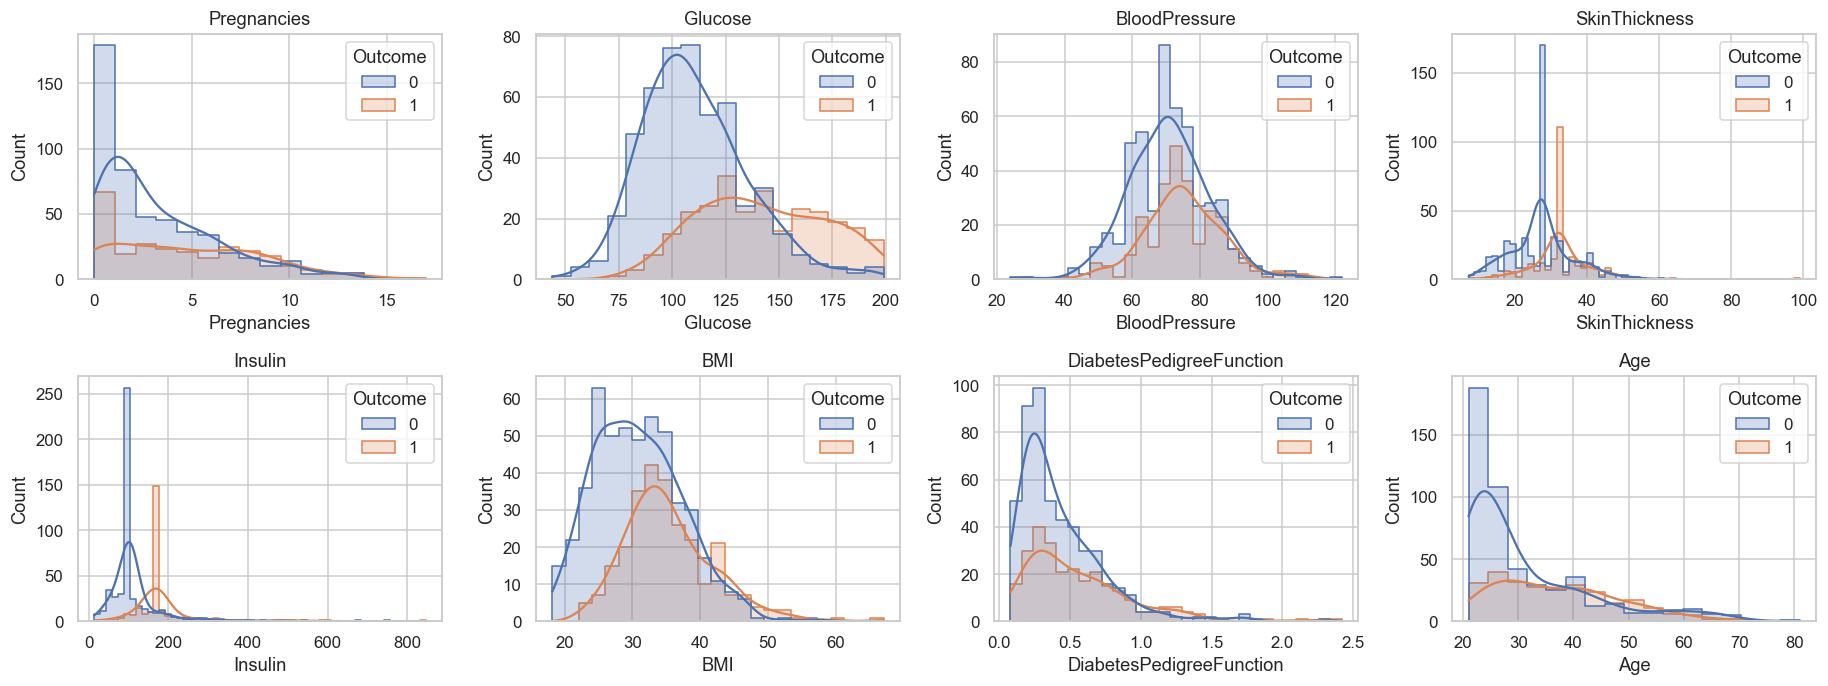

[Đã lưu] figures\s11_diabetes_hist_by_outcome.png


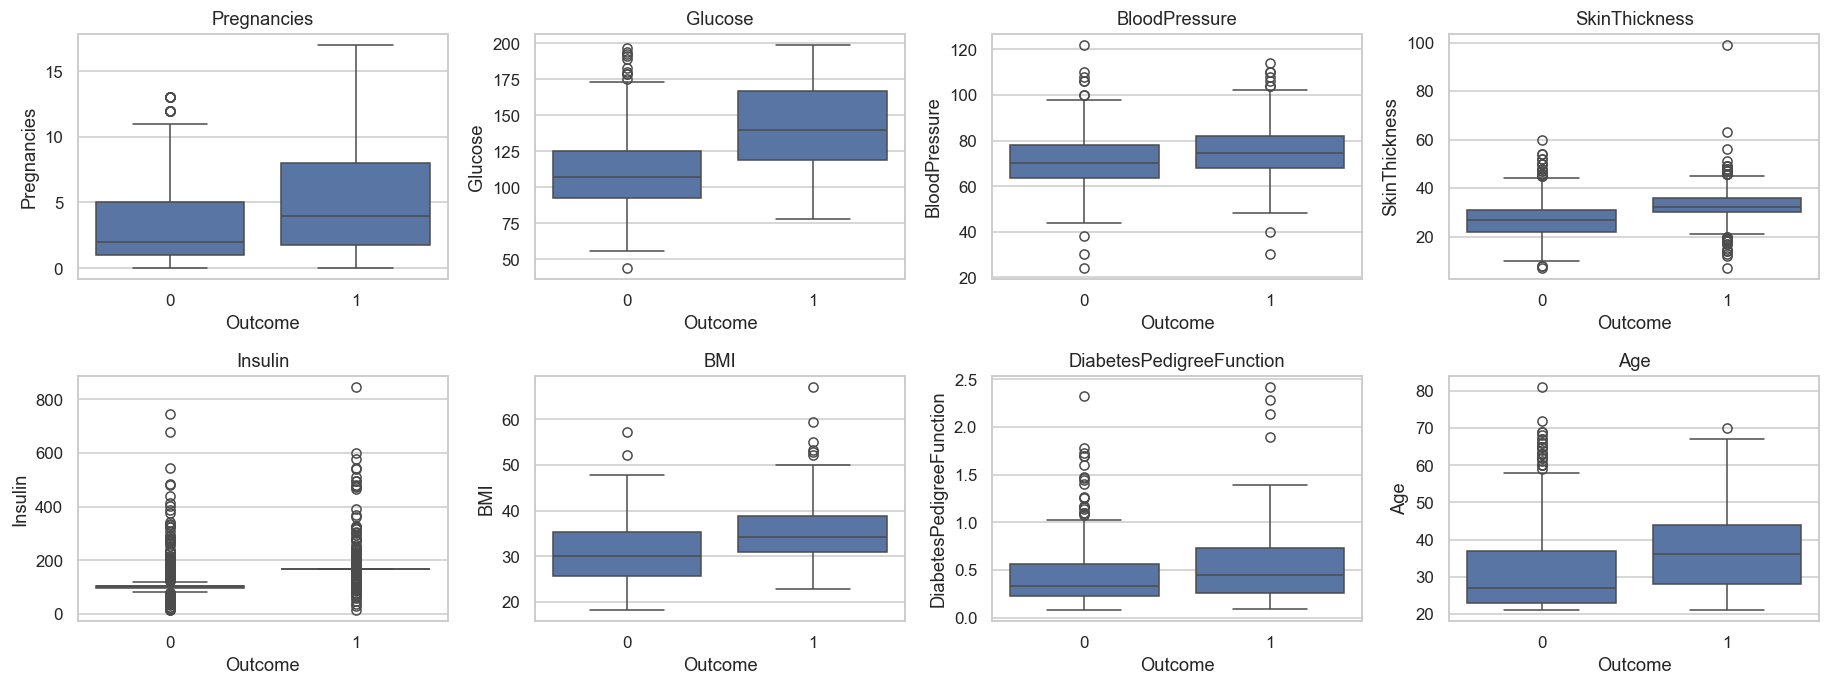

[Đã lưu] figures\s11_diabetes_box_by_outcome.png


In [21]:
feat = [c for c in db_fill.columns if c != target]
display(outlier_table(db_fill[feat]))
grid_plot(db_fill, feat, kind="hist", ncols=4, hue=target, name="s11_diabetes_hist_by_outcome")
grid_plot(db_fill, feat, kind="box", ncols=4, hue=target, name="s11_diabetes_box_by_outcome")
db_fill.to_csv(OUT_DIR / "diabetes_cleaned.csv", index=False)